In [1]:
import pandas as pd

df=pd.read_csv('House_preicecsv.csv')

print(df.head())

   area  bedrooms  bathrooms  age  location_score        price
0  1360         2          4   18               7   755.700218
1  4272         3          4   29              10  2193.330169
2  3592         1          4   13               4  1864.856083
3   966         1          4   26              10   534.157137
4  4926         2          4   19               8  2650.312781


In [2]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area            1000 non-null   int64  
 1   bedrooms        1000 non-null   int64  
 2   bathrooms       1000 non-null   int64  
 3   age             1000 non-null   int64  
 4   location_score  1000 non-null   int64  
 5   price           1000 non-null   float64
dtypes: float64(1), int64(5)
memory usage: 47.0 KB
None


In [3]:
print(df.describe())

              area     bedrooms    bathrooms          age  location_score  \
count  1000.000000  1000.000000  1000.000000  1000.000000     1000.000000   
mean   2815.422000     2.990000     2.544000    14.448000        5.503000   
std    1255.514921     1.427564     1.133732     8.592621        2.889003   
min     503.000000     1.000000     1.000000     0.000000        1.000000   
25%    1749.500000     2.000000     2.000000     7.000000        3.000000   
50%    2862.500000     3.000000     3.000000    14.000000        6.000000   
75%    3849.500000     4.000000     4.000000    22.000000        8.000000   
max    4999.000000     5.000000     4.000000    29.000000       10.000000   

             price  
count  1000.000000  
mean   1508.254446  
std     634.769078  
min     154.684979  
25%     986.953195  
50%    1549.138805  
75%    2032.838149  
max    2821.084350  


In [4]:
print(df.columns)

Index(['area', 'bedrooms', 'bathrooms', 'age', 'location_score', 'price'], dtype='object')


In [5]:
print(df.isnull().sum())

area              0
bedrooms          0
bathrooms         0
age               0
location_score    0
price             0
dtype: int64


In [6]:
x=df[['area','bedrooms','bathrooms','age','location_score']]
y=df[['price']]

print(x.head())
print(y.head())

   area  bedrooms  bathrooms  age  location_score
0  1360         2          4   18               7
1  4272         3          4   29              10
2  3592         1          4   13               4
3   966         1          4   26              10
4  4926         2          4   19               8
         price
0   755.700218
1  2193.330169
2  1864.856083
3   534.157137
4  2650.312781


In [7]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 5)
(200, 5)
(800, 1)
(200, 1)


In [8]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()

model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 5)","[[ 0.5 , 6.36, 8.89,-1.47,16.32]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['area','bedrooms','bathrooms','age','location_score']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-5.74]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,5


In [9]:
y_pred=model.predict(x_test)

print(y_pred[:5])

[[2138.51502627]
 [1333.84523365]
 [2514.60452384]
 [2508.01836138]
 [1983.22527251]]


In [10]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=mse**0.5
r2=r2_score(y_test,y_pred)

print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2 Score:",r2)

MAE: 85.3447160391618
MSE: 11490.318315489245
RMSE: 107.19290235593607
R2 Score: 0.9720131871775614


In [11]:
new_house=[[1500, 3, 2, 5, 8]]

predicted_price=model.predict(new_house)

print("Predicted House Price:",predicted_price[0])

Predicted House Price: [902.7972508]


c:\Users\Art\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


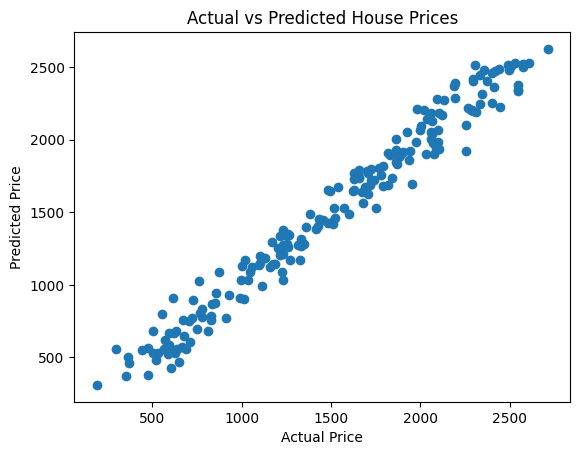

In [12]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [13]:
import pickle

with open("house_price_model.pkl", "wb") as file:
    pickle.dump(model, file)